# How well do jobs and skills pay for Data Analysts?

## Approach
1. Evaluate median salary for top 6 data jobs
2. Find median salary per skill for Data Analysts
3. Visualize highest-paying skills and most demanded skills

In [1]:

import ast
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt
from adjustText import adjust_text
import seaborn as sns

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x:ast.literal_eval(x) if pd.notna(x) else x)


In [3]:
#filter for job_titles and country
df_IN = df[(df['job_country'] == 'India')].dropna(subset=['salary_year_avg'])
df_IN.sample(5)

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
7946,Data Engineer,Data Engineering Manager,"Mysuru, Karnataka, India",via Ai-Jobs.net,Full-time,False,India,2023-07-28 13:10:54,False,False,India,year,147500.0,NaN,66degrees,"[sql, gcp, bigquery]","{'cloud': ['gcp', 'bigquery'], 'programming': ..."
584828,Machine Learning Engineer,Machine Learning Engineer,"Bengaluru, Karnataka, India",via Ai-Jobs.net,Full-time,False,India,2023-05-25 09:25:34,False,False,India,year,166000.0,NaN,Ethos,"[python, go, typescript, java, c++, aws, azure...","{'cloud': ['aws', 'azure'], 'libraries': ['ten..."
133722,Data Engineer,Customer Data Engineer,"Bengaluru, Karnataka, India",via Ai-Jobs.net,Full-time,False,India,2023-08-10 08:10:29,True,False,India,year,147500.0,NaN,Databricks,"[sql, databricks, aws, azure, gcp, spark, hado...","{'analyst_tools': ['excel'], 'cloud': ['databr..."
703529,Senior Data Engineer,Senior Data Engineer (R-15365),"Hyderabad, Telangana, India",via Ai-Jobs.net,Full-time,False,India,2023-11-22 03:12:50,False,False,India,year,155904.5,NaN,Dun & Bradstreet,"[python, sql, aws, azure, react]","{'cloud': ['aws', 'azure'], 'libraries': ['rea..."
312085,Software Engineer,"Sr Software Engineer(Power bi, SSRS)","Pune, Maharashtra, India",via Ai-Jobs.net,Full-time,False,India,2023-09-04 17:08:43,True,False,India,year,79200.0,NaN,Altera Digital Health,"[python, r, sql, sql server, oracle, node.js, ...","{'analyst_tools': ['ssis', 'dax', 'power bi'],..."


In [8]:
job_titles = df_IN['job_title_short'].value_counts().index[:6].tolist()
job_titles

['Data Engineer',
 'Data Analyst',
 'Data Scientist',
 'Machine Learning Engineer',
 'Senior Data Engineer',
 'Software Engineer']

In [11]:
df_IN_top6 = df_IN[df_IN['job_title_short'].isin(job_titles)]
df_IN_top6.sample(6)

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
159676,Data Engineer,Senior Software Engineer - Data Engineering (J...,"Bengaluru, Karnataka, India",via Ai-Jobs.net,Full-time,False,India,2023-08-01 08:20:18,False,False,India,year,147500.0,NaN,Zscaler,"[java, nosql, neo4j, redshift, aws, spring, sp...","{'analyst_tools': ['excel'], 'cloud': ['redshi..."
596078,Data Analyst,Process and Data Analyst,"Bengaluru, Karnataka, India",via Ai-Jobs.net,Full-time,False,India,2023-06-27 09:34:23,False,False,India,year,111175.0,NaN,Bosch Group,"[sql, python, sap]","{'analyst_tools': ['sap'], 'programming': ['sq..."
705174,Machine Learning Engineer,"Machine Learning Engineer | Hybrid, Bangalore,...","Bengaluru, Karnataka, India",via Ai-Jobs.net,Full-time,False,India,2023-04-06 03:13:26,False,False,India,year,166000.0,NaN,Optiv,"[python, java, keras, pytorch]","{'libraries': ['keras', 'pytorch'], 'programmi..."
646661,Data Engineer,Big Data Engineer,"Bengaluru, Karnataka, India",via Ai-Jobs.net,Full-time,False,India,2023-08-07 12:53:25,True,False,India,year,45000.0,NaN,SiteMinder,"[python, sql, aws, redshift, aurora, gcp, azur...","{'analyst_tools': ['tableau'], 'cloud': ['aws'..."
61483,Data Analyst,Executive - Credit Controller and Project Data...,"Hyderabad, Telangana, India",via Ai-Jobs.net,Full-time,False,India,2023-07-20 06:12:20,False,False,India,year,105000.0,NaN,Ramboll,"[excel, power bi]","{'analyst_tools': ['excel', 'power bi']}"
764449,Data Engineer,Solution Architect – Big Data,"Chennai, Tamil Nadu, India",via Ai-Jobs.net,Full-time,False,India,2023-06-20 20:11:23,False,False,India,year,79200.0,NaN,Smartek21.com,"[java, scala, aws, azure, hadoop]","{'cloud': ['aws', 'azure'], 'libraries': ['had..."


In [17]:
job_order= df_IN_top6.groupby('job_title_short')['salary_year_avg'].median().sort_values(ascending=False).index.tolist()
job_order

['Data Engineer',
 'Senior Data Engineer',
 'Data Scientist',
 'Data Analyst',
 'Machine Learning Engineer',
 'Software Engineer']

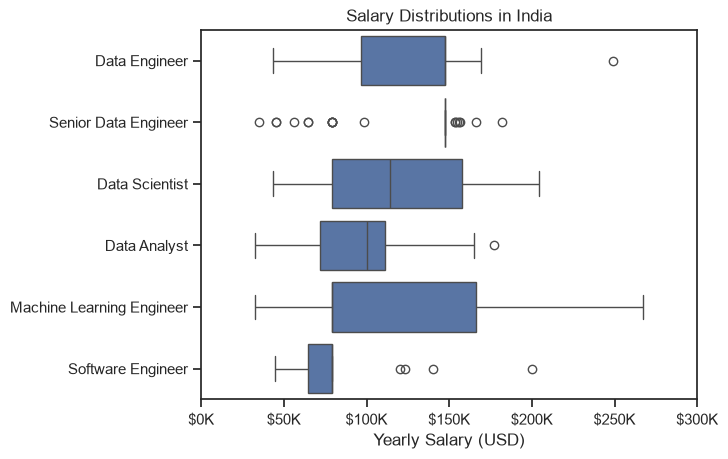

In [18]:
sns.boxplot(data=df_IN_top6, x='salary_year_avg', y='job_title_short', order=job_order)
sns.set_theme(style='ticks')

# this is all the same
plt.title('Salary Distributions in India')
plt.xlabel('Yearly Salary (USD)')
plt.ylabel('')
plt.xlim(0, 300000) 
ticks_x = plt.FuncFormatter(lambda y, pos: f'${int(y/1000)}K')
plt.gca().xaxis.set_major_formatter(ticks_x)
plt.show()

# Investigate Median Salary VS Skills for Data Analyst


In [28]:
df_DA_IN = df[
    (df['job_country'] == 'India') &
    (df['job_title_short'] == 'Data Analyst')
].copy()

df_DA_IN = df_IN.dropna(subset=['salary_year_avg'])

df_DA_IN.sample(5)

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
597416,Data Analyst,Data Analyst,"Chennai, Tamil Nadu, India",via Ai-Jobs.net,Full-time,False,India,2023-07-28 09:10:41,True,False,India,year,111175.0,NaN,Freshworks,"[excel, powerpoint, power bi, tableau]","{'analyst_tools': ['excel', 'powerpoint', 'pow..."
785515,Data Analyst,Data Analyst,"Bengaluru, Karnataka, India",via Ai-Jobs.net,Full-time,False,India,2023-09-01 06:17:34,False,False,India,year,105000.0,NaN,Myntra,NaN,NaN
306374,Data Analyst,Business/Data Analyst,"Gurugram, Haryana, India",via Ai-Jobs.net,Full-time,False,India,2023-07-13 17:11:57,False,False,India,year,57500.0,NaN,Miratech,[sheets],{'analyst_tools': ['sheets']}
247012,Data Analyst,Data Integration and Business Intelligence Ana...,India,via Ai-Jobs.net,Full-time,False,India,2023-07-27 07:12:37,False,False,India,year,79200.0,NaN,Miratech,"[sql, unix, windows, tableau]","{'analyst_tools': ['tableau'], 'os': ['unix', ..."
425249,Data Analyst,HR Data Operations Analyst,India,via Ai-Jobs.net,Full-time,False,India,2023-11-07 16:10:40,False,False,India,year,104550.0,NaN,Clarivate,"[word, excel, powerpoint]","{'analyst_tools': ['word', 'excel', 'powerpoin..."


In [ ]:
df_DA_IN = df_DA_IN.explode('job_skills')


,salary_year_avg,job_skills
11412,50400.0,python
11412,50400.0,sql
11412,50400.0,aws
11412,50400.0,azure
11412,50400.0,excel


In [39]:
df_DA_top_pay = df_DA_IN.groupby('job_skills')['salary_year_avg'].agg(['count','median']).sort_values(by = 'median', ascending=False)

df_DA_top_pay = df_DA_top_pay.head(10)
df_DA_top_pay 

,count,median
job_skills,,
postgresql,1,165000.0
pyspark,1,165000.0
gitlab,1,165000.0
linux,1,165000.0
mysql,1,165000.0
gdpr,2,163782.0
mongodb,6,163782.0
scala,3,163782.0
neo4j,1,163782.0


In [40]:
df_DA_skills = df_DA_IN.groupby('job_skills')['salary_year_avg'].agg(['count','median']).sort_values(by = 'count', ascending=False)

df_DA_skills = df_DA_skills.head(10)
df_DA_skills 

,count,median
job_skills,,
sql,46,96050.0
excel,39,98500.0
python,36,96050.0
tableau,20,108087.5
r,18,79200.0
power bi,17,111175.0
azure,15,93600.0
aws,12,79200.0
oracle,11,79200.0


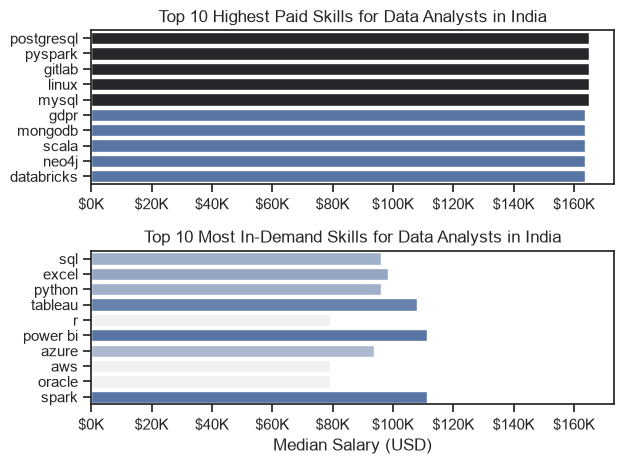

In [53]:
fig, ax = plt.subplots(2, 1)  

sns.set_theme(style='ticks')

# Top 10 Highest Paid Skills for Data Analysts
sns.barplot(data=df_DA_top_pay, x='median', y=df_DA_top_pay.index, hue='median', ax=ax[0], palette='dark:b_r')
ax[0].legend().remove()
# original code:
# df_DA_top_pay[::-1].plot(kind='barh', y='median', ax=ax[0], legend=False) 
ax[0].set_title('Top 10 Highest Paid Skills for Data Analysts in India')
ax[0].set_ylabel('')
ax[0].set_xlabel('')
ax[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${int(x/1000)}K'))


# Top 10 Most In-Demand Skills for Data Analyst')
sns.barplot(data=df_DA_skills, x='median', y=df_DA_skills.index, hue='median', ax=ax[1], palette='light:b')
ax[1].legend().remove()
# original code:
# df_DA_skills[::-1].plot(kind='barh', y='median', ax=ax[1], legend=False)
ax[1].set_title('Top 10 Most In-Demand Skills for Data Analysts in India')
ax[1].set_ylabel('')
ax[1].set_xlabel('Median Salary (USD)')
ax[1].set_xlim(ax[0].get_xlim())  # Set the same x-axis limits as the first plot
ax[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${int(x/1000)}K'))

plt.tight_layout()
plt.show()